# 05 Buildings
 The hidden building gap compares Overture's count with an external footprint count, so what matters is which tracts' counts are most likely to fall short and whether that can be seen from inside Overture.

In [1]:
from common import *
import duckdb
b = pd.read_parquet(OUT / "base_table.parquet")
s = b[b.region.isin(SCORED)]
c = duckdb.connect(); c.sql("load spatial"); c.sql("set geometry_always_xy = true")
BF = lambda r: f"read_parquet('{(REF/r/f'{r}-overture-buildings.parquet').as_posix()}')"
sup = pd.concat([c.sql(f"select '{r}' region, sources[1].dataset supplier, count(*) n from {BF(r)} group by 1,2").df() for r in REG])
sup["share"] = sup.n / sup.groupby("region").n.transform("sum")
print(sup.pivot(index="supplier", columns="region", values="share")[REG].fillna(0).round(3).to_string())
print("\nbuildings:", sup.groupby("region").n.sum()[REG].to_dict())

region                  maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
supplier                                                                                  
Esri Community Maps           0.047        0.026       0.140             0.024       0.060
Google Open Buildings         0.013        0.000       0.000             0.022       0.000
Microsoft ML Buildings        0.143        0.508       0.694             0.443       0.381
OpenStreetMap                 0.797        0.466       0.167             0.510       0.559

buildings: {'maricopa-az': 2908224, 'northern-ca': 1164724, 'eastern-ok': 2551694, 'south-central-tx': 11463801, 'eastern-wa': 1081346}


## 1. Attribute completeness and age, by supplier

In [2]:
rows = []
for r in REG:
    rows.append(c.sql(f"""select '{r}' region, sources[1].dataset supplier, count(*) n,
        avg((height is not null)::int) height, avg((num_floors is not null)::int) floors, avg((class is not null)::int) class,
        avg((subtype is not null)::int) subtype, avg((names."primary" is not null)::int) named, avg((roof_shape is not null)::int) roof_shape,
        median(try_cast(substr(sources[1].update_time,1,4) as integer)) median_update_year,
        avg((try_cast(substr(sources[1].update_time,1,4) as integer) >= 2024)::int) updated_2024plus,
        median(ST_Area_Spheroid(geometry)) median_area_m2, avg((ST_Area_Spheroid(geometry) < 30)::int) under30m2
        from (select * from {BF(r)} using sample 10% (reservoir, 7)) group by 2""").df())
att = pd.concat(rows)
tot = att.groupby("supplier").apply(lambda d: pd.Series({k: np.average(d[k].astype(float), weights=d.n) for k in ["height", "floors", "class", "subtype", "named", "roof_shape", "median_update_year", "updated_2024plus", "median_area_m2", "under30m2"]} | {"sample_n": d.n.sum()}))
print(tot.round(3).to_string())

                        height  floors  class  subtype  named  roof_shape  median_update_year  updated_2024plus  median_area_m2  under30m2    sample_n
supplier                                                                                                                                              
Esri Community Maps      0.396   0.000  0.008    0.008  0.002       0.000           2,025.000             1.000          77.472      0.374  86,808.000
Google Open Buildings    0.130   0.000  0.000    0.000  0.000       0.000           2,023.000             0.000          33.127      0.462  29,061.000
Microsoft ML Buildings   0.769   0.000  0.000    0.000  0.000       0.000           2,021.629             0.013         171.115      0.030 830,374.000
OpenStreetMap            0.779   0.012  0.380    0.385  0.017       0.005           2,021.249             0.276         220.309      0.034 978,137.000


## 2. Where each supplier dominates
Supplier shares by urban class (Census urban/rural of the tract) and by region. Microsoft is the reference the hidden building gap uses, so its share says how much of a tract's Overture count is, in effect, the reference itself.

In [3]:
share = s.copy()
for k in ["msft", "osm", "esri", "google", "other"]: share[f"sh_{k}"] = share[f"bldg_n_{k}"] / share.bldg_n.where(share.bldg_n > 0)
share["ur"] = share.ur_class.fillna("unclassified")
print("mean tract-level supplier share by urban class:"); print(share.groupby("ur")[["sh_msft", "sh_osm", "sh_esri", "sh_google", "sh_other"]].mean().round(3).to_string())
print("\nby region:"); print(share.groupby("region")[["sh_msft", "sh_osm", "sh_esri", "sh_google", "sh_other"]].mean().loc[SCORED].round(3).to_string())
print("\ntracts where Microsoft is >= 80% of buildings:", int((share.sh_msft >= .8).sum()), "of", len(share), "| where one supplier is >= 95%:", int((share[["sh_msft", "sh_osm", "sh_esri", "sh_google", "sh_other"]].max(axis=1) >= .95).sum()))
print("urban class counts:", share.ur.value_counts().to_dict())

mean tract-level supplier share by urban class:
              sh_msft  sh_osm  sh_esri  sh_google  sh_other
ur                                                         
Rural           0.727   0.237    0.028      0.008     0.000
Urban           0.303   0.643    0.040      0.014     0.000
unclassified    0.201   0.719    0.034      0.047     0.000

by region:
                  sh_msft  sh_osm  sh_esri  sh_google  sh_other
region                                                         
maricopa-az         0.132   0.833    0.026      0.009     0.000
northern-ca         0.453   0.524    0.023      0.000     0.000
eastern-ok          0.640   0.209    0.151      0.000     0.000
south-central-tx    0.387   0.575    0.020      0.018     0.000

tracts where Microsoft is >= 80% of buildings: 2459 of 9379 | where one supplier is >= 95%: 3290
urban class counts: {'Urban': 7641, 'Rural': 1712, 'unclassified': 26}


## 3. Buildings against housing units and land
ACS counts housing units; Microsoft and Overture count structures. How well does housing explain the building count, and does the ratio differ with density?

log-log correlation, buildings vs housing units: 0.42 | vs land area: 0.642

buildings per housing unit by housing-density octile:
                                median  mean  count
hu_per_km2                                         
(0.0003699999999999999, 12.13]   2.210 2.620   1163
(12.13, 88.197]                  1.550 1.640   1162
(88.197, 253.366]                1.190 1.220   1162
(253.366, 437.729]               1.050 1.050   1163
(437.729, 617.631]               0.980 0.970   1162
(617.631, 797.621]               0.950 0.930   1162
(797.621, 1076.026]              0.830 0.830   1162
(1076.026, 10193.647]            0.420 0.470   1163


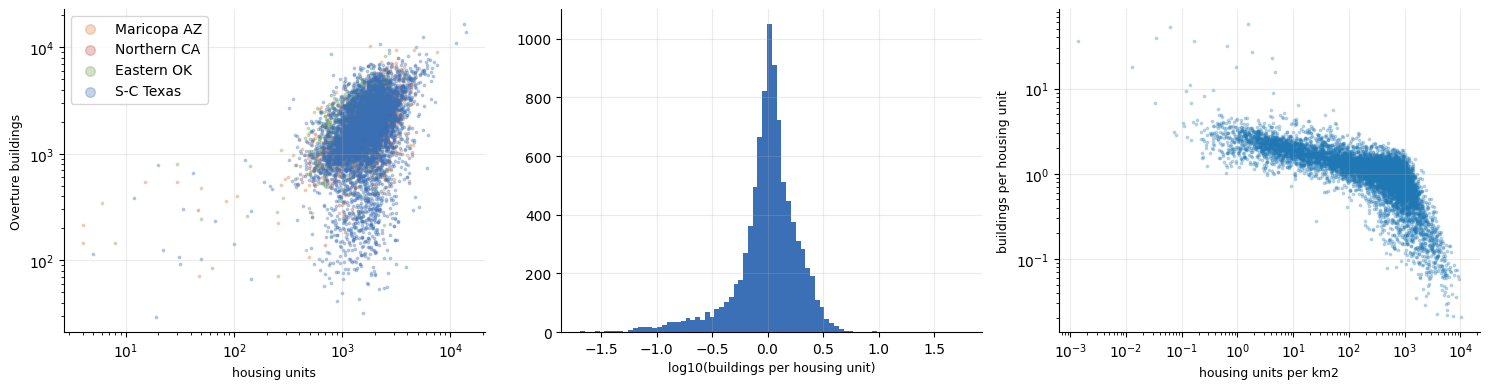

In [4]:
x = s[(s.housing_units > 0) & (s.bldg_n > 0)]
print("log-log correlation, buildings vs housing units:", round(np.corrcoef(np.log(x.housing_units), np.log(x.bldg_n))[0, 1], 3), "| vs land area:", round(np.corrcoef(np.log(x.land_km2), np.log(x.bldg_n))[0, 1], 3))
dens = pd.qcut(x.hu_per_km2, 8, duplicates="drop")
print("\nbuildings per housing unit by housing-density octile:"); print(x.groupby(dens).bldg_per_hu.agg(["median", "mean", "count"]).round(2).to_string())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r in SCORED: q = s[(s.region == r) & (s.housing_units > 0) & (s.bldg_n > 0)]; ax[0].scatter(q.housing_units, q.bldg_n, s=3, alpha=.3, c=COL[r], label=NAME[r])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("housing units"); ax[0].set_ylabel("Overture buildings"); ax[0].legend(markerscale=4)
ax[1].hist(np.log10(x.bldg_per_hu), bins=80, color="#3b6fb6"); ax[1].set_xlabel("log10(buildings per housing unit)")
ax[2].scatter(x.hu_per_km2, x.bldg_per_hu, s=3, alpha=.25); ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("housing units per km2"); ax[2].set_ylabel("buildings per housing unit")
plt.show()

**Takeaway:** Housing units explain buildings poorly: the log-log correlation is 0.42, lower than with land area (0.64). Buildings per housing unit falls steadily with housing density, from a median of 2.21 in the sparsest octile (under 12 housing units per km2) to 0.42 in the densest (over 1,076 per km2), because rural parcels hold outbuildings and dense tracts hold apartments. This is consistent with the organisers excluding ACS from the building ratio, and it means a building expectation needs land and density as well as housing.

## 4. Small footprints and tract-level quality signals
Footprints under 30 m2 are mostly sheds and outbuildings. Their share, together with attribute completeness and record age, is a quality signal available for every tract.

In [5]:
q = s[s.bldg_n > 0].copy()
q["small_share"] = q.bldg_n_lt30m2 / q.bldg_n; q["height_share"] = q.bldg_n_height / q.bldg_n; q["floors_share"] = q.bldg_n_floors / q.bldg_n
q["class_share"] = q.bldg_n_class / q.bldg_n; q["named_share"] = q.bldg_n_name / q.bldg_n; q["new_share"] = q.bldg_n_upd_ge2024 / q.bldg_n
print(q.groupby("region")[["small_share", "height_share", "floors_share", "class_share", "named_share", "new_share", "bldg_year_median"]].median().loc[SCORED].round(3).to_string())
print("\nspread across tracts (pooled):"); print(q[["small_share", "height_share", "class_share", "new_share"]].describe(percentiles=[.1, .5, .9]).round(3).to_string())
print("\ncorrelation of tract-level quality signals with housing density (Spearman):")
print(q[["small_share", "height_share", "class_share", "new_share", "bldg_src_n"]].corrwith(q.hu_per_km2, method="spearman").round(3).to_string())

                  small_share  height_share  floors_share  class_share  named_share  new_share  bldg_year_median
region                                                                                                          
maricopa-az             0.020         0.969         0.001        0.276        0.006      0.046         2,023.000
northern-ca             0.025         0.885         0.000        0.032        0.003      0.077         2,022.000
eastern-ok              0.029         0.734         0.000        0.020        0.004      0.080         2,021.000
south-central-tx        0.017         0.856         0.000        0.041        0.005      0.040         2,021.000

spread across tracts (pooled):
       small_share  height_share  class_share  new_share
count    9,377.000     9,377.000    9,377.000  9,377.000
mean         0.046         0.792        0.246      0.181
std          0.069         0.204        0.332      0.265
min          0.000         0.000        0.000      0.000
10%  

small_share    -0.278
height_share    0.437
class_share     0.343
new_share       0.138
bldg_src_n     -0.017


**Takeaway:** Tract-level quality signals track density: the share of footprints with a height rises from a median of 73% in Eastern OK to 97% in Maricopa, class is filled for a median of 5% of buildings overall but 28% in Maricopa, and names for under 1%. Across tracts, height share correlates +0.44 with housing density, class share +0.34, the share of tiny footprints -0.28 and the share updated since 2024 +0.14, while the number of suppliers is unrelated (-0.02). Detail in the data therefore rises with urbanity, so low detail should not be read as low coverage.